# Лабораторна робота № 6
## AutoML і ручне моделювання: контрольоване порівняння
**Ковальчук · ІПЗс-24-1 · варіант 5 · Бедратюк Л.П.**

Breast Cancer Wisconsin (Diagnostic), `sklearn.load_breast_cancer`; позитивний клас y=1 — malignant.
Набір обрано для наступності з варіантом 5, ЛР № 5 і ПР № 5–6; методичка ЛР № 6 (п. 4.1) таблиці варіантів не містить.
Цей набір уже використовувався в попередніх роботах курсу, тому test незалежний лише в межах цього експерименту.
Не діагностичний інструмент: клінічне використання заборонено.

Notebook **нічого не навчає і не шукає заново**: він читає збережені CSV/JSON/PNG і перевіряє їхню узгодженість.
Код і результати отримано в сесії Claude Code (див. `AI_USAGE.md`); студент відповідає за перевірку результату.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
from IPython.display import display,Image
ROOT=Path.cwd() if (Path.cwd()/'results').is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import experiment as E
def table(name): return pd.read_csv(ROOT/'results'/f'{name}.csv')
def record(name): return json.loads((ROOT/'results'/f'{name}.json').read_text(encoding='utf-8'))
def picture(name): display(Image(filename=str(ROOT/'figures'/f'{name}.png')))
display(record('environment'))
display(record('train_eda'))

{'python': '3.12.0',
 'platform': 'Windows-11-10.0.26200-SP0',
 'sklearn': '1.9.0',
 'numpy': '2.2.3',
 'pandas': '3.0.5',
 'scipy': '1.15.3',
 'flaml': '2.3.6',
 'threads': 1,
 'warnings_policy': 'Warnings are treated as errors by the validation runner.'}

{'train_n': 455,
 'features': 30,
 'positive_n': 170,
 'missing_n': 0,
 'constant_features': [],
 'min': 0.0,
 'max': 4254.0,
 'positive_class': 'malignant (y=1)'}

## 1. Постановка та протокол до результатів
Користувач — експерт/оператор лабораторії, який переглядає записи FNA; результат — ймовірність malignant і ранжування для ручної перевірки.
Це не діагноз і не автоматичне клінічне рішення.
AP — основна метрика: вона не залежить від порога й оцінює, наскільки високо ранжовані позитивні записи.
Додаткові: ROC-AUC, F1, precision, recall, balanced accuracy, Brier, log loss; поріг 0.5 заданий до запуску.

Holdout 20% (stratify, seed=42). На решті — nested CV: 5 зовнішніх × 3 внутрішніх folds.
Кожна гілка має 12 кандидатів, один потік, однакові індекси та `SimpleImputer → StandardScaler → модель`.
Практична межа ε=0.01 AP; якщо середня парна різниця не перевищує її, tie-break: розмір → p95 latency → Manual.
Це правило рішення, а не статистичний доказ еквівалентності.

In [2]:
cfg=json.loads((ROOT/'configs/experiment.json').read_text(encoding='utf-8'))
display(cfg)
assert cfg['test_used_for_search'] is False and cfg['test_used_for_selection'] is False
contract=record('search_contract')
display(pd.DataFrame([{'candidate_id':s['candidate_id'],'family':s['family'],'params':json.dumps(s['params'])} for s in contract['manual']]))
display(pd.DataFrame({k:{p:str(v) for p,v in d.items()} for k,d in contract['flaml_space'].items()}).T)
splits=table('split_ids')
assert not set(splits[splits.part.eq('train')].id)&set(splits[splits.part.eq('test')].id)
assert sorted(splits.id)==list(range(569))
X,y,names=E.load_data()
tr=splits[splits.part.eq('train')].id.to_numpy();te=splits[splits.part.eq('test')].id.to_numpy()
assert (len(tr),len(te))==(455,114) and (int(y[tr].sum()),int(y[te].sum()))==(170,42)
display(pd.DataFrame({'n':[len(tr),len(te)],'malignant':[int(y[tr].sum()),int(y[te].sum())]},index=['train','test']))

{'dataset': 'sklearn.load_breast_cancer (UCI Breast Cancer Wisconsin Diagnostic)',
 'target': 'diagnosis == malignant',
 'seed': 42,
 'test_size': 0.2,
 'outer_folds': 5,
 'inner_folds': 3,
 'budget': 12,
 'primary_metric': 'ap',
 'epsilon': 0.01,
 'threshold': 0.5,
 'stability_seeds': [42, 43, 44],
 'n_jobs': 1,
 'test_used_for_search': False,
 'test_used_for_selection': False,
 'tie_break': 'smaller serialized pipeline, then lower p95 single latency, then manual',
 'families': ['lrl2', 'rf', 'extra_tree', 'histgb', 'kneighbor'],
 'preprocessing': 'SimpleImputer(median, keep_empty_features=True) -> StandardScaler -> estimator; fit inside every inner fold',
 'failed_trial_policy': 'abort on error, nonfinite loss, fewer than 12 completed trials or fit-count mismatch'}

,candidate_id,family,params
0,manual_00,lrl2,"{""C"": 0.01}"
1,manual_01,lrl2,"{""C"": 0.1}"
2,manual_02,lrl2,"{""C"": 1.0}"
3,manual_03,lrl2,"{""C"": 10.0}"
4,manual_04,rf,"{""n_estimators"": 64, ""max_depth"": 5, ""min_samp..."
5,manual_05,rf,"{""n_estimators"": 64, ""max_depth"": 10, ""min_sam..."
6,manual_06,rf,"{""n_estimators"": 64, ""max_depth"": null, ""min_s..."
7,manual_07,rf,"{""n_estimators"": 64, ""max_depth"": null, ""min_s..."
8,manual_08,histgb,"{""learning_rate"": 0.03, ""max_iter"": 100, ""max_..."
9,manual_09,histgb,"{""learning_rate"": 0.1, ""max_iter"": 100, ""max_l..."


,C,class_weight,n_estimators,max_depth,min_samples_leaf,max_iter,learning_rate,max_leaf_nodes,n_neighbors,weights
lrl2,"[0.01, 0.1, 1.0, 10.0]","[None, 'balanced']",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rf,NaN,NaN,"[32, 64, 128]","[5, 10, None]","[1, 3, 5]",NaN,NaN,NaN,NaN,NaN
extra_tree,NaN,NaN,"[32, 64, 128]","[5, 10, None]","[1, 3, 5]",NaN,NaN,NaN,NaN,NaN
histgb,NaN,NaN,NaN,NaN,NaN,"[50, 100, 150]","[0.03, 0.1, 0.2]","[7, 15, 31]",NaN,NaN
kneighbor,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[3, 5, 9, 15]","['uniform', 'distance']"


,n,malignant
train,455,170
test,114,42


## 2. Дані, походження та повторне використання
Джерело, ліцензія CC BY 4.0, хеш сирих даних і примітка про повторне використання — у `data_provenance.json`.
Для 114 test-ID перетин зі split ЛР № 5 порахований лише за ID (ознаки й моделі ЛР № 5 не читалися).
Конфігурація простору, метрики, ε і tie-break зафіксована до цього запуску й не підбиралась за результатами попередніх робіт.

In [3]:
provenance=record('data_provenance');display(provenance)
assert provenance['raw_x_target_sha256']==E.raw_data_sha256()
assert provenance['n']==569 and provenance['duplicate_rows']==0
ov=provenance['lab05_split_overlap']
assert ov['lab06_test_ids_in_lab05_train']+ov['lab06_test_ids_in_lab05_test']==ov['lab06_test_n']
print('lab06 test IDs: in lab05 train =',ov['lab06_test_ids_in_lab05_train'],', in lab05 test =',ov['lab06_test_ids_in_lab05_test'])

{'source': 'UCI Breast Cancer Wisconsin (Diagnostic)',
 'url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic',
 'authors': 'W. Wolberg, W. Street, O. Mangasarian',
 'license': 'CC BY 4.0',
 'access': 'sklearn.datasets.load_breast_cancer',
 'sklearn_version': '1.9.0',
 'n': 569,
 'n_features': 30,
 'class_counts': {'malignant': 212, 'benign': 357},
 'raw_x_target_sha256': '25e2eb7b7a8745b1bde5ba18bc4969983d2e2f403291ecd5bde4a29ef30c3859',
 'raw_hash_definition': 'sha256(ascontiguousarray(data).tobytes() + ascontiguousarray(target).tobytes()) of load_breast_cancer',
 'duplicate_rows': 0,
 'object_id': 'row index in load_breast_cancer',
 'reuse_note': 'The same public dataset was used in earlier course labs (lab01, lab05, practical05/06), so the lab06 test part is untouched only within this experiment. The lab06 search space, metric, epsilon and tie-break were fixed in the config before this run and were not tuned on results of earlier labs.',
 'lab05_split_ov

lab06 test IDs: in lab05 train = 90 , in lab05 test = 24


## 3. Дві процедури пошуку та бюджет
Manual: 12 наперед заданих конфігурацій (4 LogisticRegression, 4 RandomForest, 4 HistGradientBoosting), усі оцінені на тих самих inner folds.
AutoML: готовий FLAML 2.3.6 (CFO, `learner_selector='roundrobin'`, `max_iter=12`, `metric='ap'`, `log_type='all'`), п'ять сімейств.
Власні адаптери лише забезпечують fold-local Pipeline; конфігурації обирає FLAML.

In [4]:
hist=table('candidate_history')
display(hist.groupby(['stage','branch']).agg(trials=('trial','size'),best_inner_ap=('inner_ap','max')).round(6))
budget=table('budget_audit')
display(budget.round(4))
audit=table('flaml_fit_audit')
assert (audit.n==audit.scaler_n).all() and len(audit)==296
assert (budget.candidates==12).all() and (budget.cv_fits==36).all()
assert (budget[budget.branch.eq('automl')].framework_refits==1).all() and (budget[budget.branch.eq('manual')].framework_refits==0).all()
assert len(hist)==192
for path in sorted((ROOT/'results/logs').glob('*.jsonl')):
    n=sum('validation_loss' in json.loads(s) for s in path.read_text(encoding='utf-8').splitlines())
    assert n==12,(path.name,n)
print('Search seconds total:',budget.groupby('branch').search_seconds.sum().round(3).to_dict())
print('Mean trial seconds by family:');display(hist.groupby(['branch','family']).seconds.mean().round(3))

trials  best_inner_ap
stage         branch                       
final_seed_42 automl      12       0.993049
              manual      12       0.994760
final_seed_43 automl      12       0.993400
              manual      12       0.993573
final_seed_44 automl      12       0.993611
              manual      12       0.993473
outer_0       automl      12       0.992525
              manual      12       0.993517
outer_1       automl      12       0.989901
              manual      12       0.989901
outer_2       automl      12       0.989892
              manual      12       0.990728
outer_3       automl      12       0.995011
              manual      12       0.996078
outer_4       automl      12       0.990510
              manual      12       0.990510

,stage,branch,candidates,inner_folds,cv_fits,framework_refits,search_seconds,threads
0,outer_0,manual,12,3,36,0,2.9816,1
1,outer_0,automl,12,3,36,1,1.2903,1
2,outer_1,manual,12,3,36,0,3.1078,1
3,outer_1,automl,12,3,36,1,1.4181,1
4,outer_2,manual,12,3,36,0,2.9110,1
5,outer_2,automl,12,3,36,1,1.2090,1
6,outer_3,manual,12,3,36,0,2.7687,1
7,outer_3,automl,12,3,36,1,1.1381,1
8,outer_4,manual,12,3,36,0,2.8565,1
9,outer_4,automl,12,3,36,1,1.3359,1


Search seconds total: {'automl': 11.074, 'manual': 25.085}
Mean trial seconds by family:


branch  family    
automl  extra_tree    0.134
        histgb        0.187
        kneighbor     0.020
        lrl2          0.025
        rf            0.199
manual  histgb        0.390
        lrl2          0.025
        rf            0.369
Name: seconds, dtype: float64

Бюджет порівняння кандидатів однаковий: 12 кандидатів × 3 inner folds = 36 CV-fit на пошук. FLAML додатково робить один
внутрішній refit; наш контур потім однаково перевчає переможця кожної гілки. Час наведено без нормування: він залежить
від складу простору й початкових значень, а не лише від «якості» методу. Невдалий trial, нечислова втрата чи неповний бюджет зупиняють запуск.

## 4. Зовнішня якість, парні різниці та невизначеність

,fold,branch,ap,roc_auc,f1,precision,recall,balanced_accuracy,brier,log_loss
0,0,baseline,0.3736,0.5000,0.0000,0.0000,0.0000,0.5000,0.2340,0.6609
1,0,manual,0.9919,0.9948,0.9375,1.0000,0.8824,0.9412,0.0296,0.0940
2,0,automl,0.9954,0.9969,0.9206,1.0000,0.8529,0.9265,0.0303,0.1138
3,1,baseline,0.3736,0.5000,0.0000,0.0000,0.0000,0.5000,0.2340,0.6609
4,1,manual,0.9984,0.9990,0.9565,0.9429,0.9706,0.9678,0.0169,0.0702
5,1,automl,0.9984,0.9990,0.9565,0.9429,0.9706,0.9678,0.0169,0.0702
6,2,baseline,0.3736,0.5000,0.0000,0.0000,0.0000,0.5000,0.2340,0.6609
7,2,manual,0.9886,0.9923,0.9231,0.9677,0.8824,0.9324,0.0413,0.1387
8,2,automl,0.9984,0.9990,0.9697,1.0000,0.9412,0.9706,0.0250,0.0996
9,3,baseline,0.3736,0.5000,0.0000,0.0000,0.0000,0.5000,0.2340,0.6609


,branch,ap_mean,ap_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,recall_mean,recall_std,precision_mean,precision_std,brier_mean,brier_std,log_loss_mean,log_loss_std
0,automl,0.9942,0.0058,0.9949,0.0063,0.9603,0.0244,0.9353,0.0483,0.9886,0.0256,0.025,0.0062,0.1011,0.0244
1,baseline,0.3736,0.0000,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.234,0.0000,0.6609,0.0000
2,manual,0.9922,0.0044,0.9938,0.0045,0.9544,0.0247,0.9294,0.0446,0.9821,0.0260,0.026,0.0097,0.0993,0.0254


{'difference_automl_minus_manual': [0.0034648418190804664,
  0.0,
  0.009800624149899684,
  -0.0032711006764651884,
  0.0],
 'mean_difference': 0.0019988730585029924,
 'bootstrap_interval_95': [-0.0013084402705860754, 0.005999154751408153],
 'epsilon': 0.01,
 'interval_limitation': 'Five dependent folds; descriptive fold bootstrap, not independent-sample CI or equivalence proof.'}

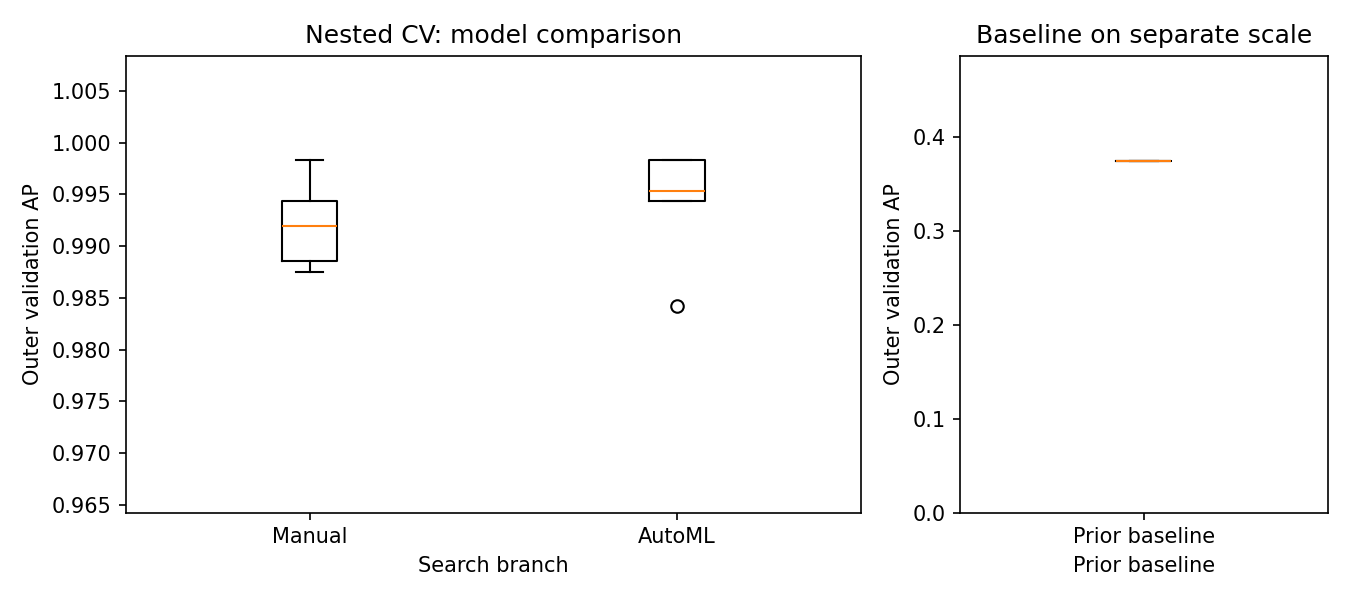

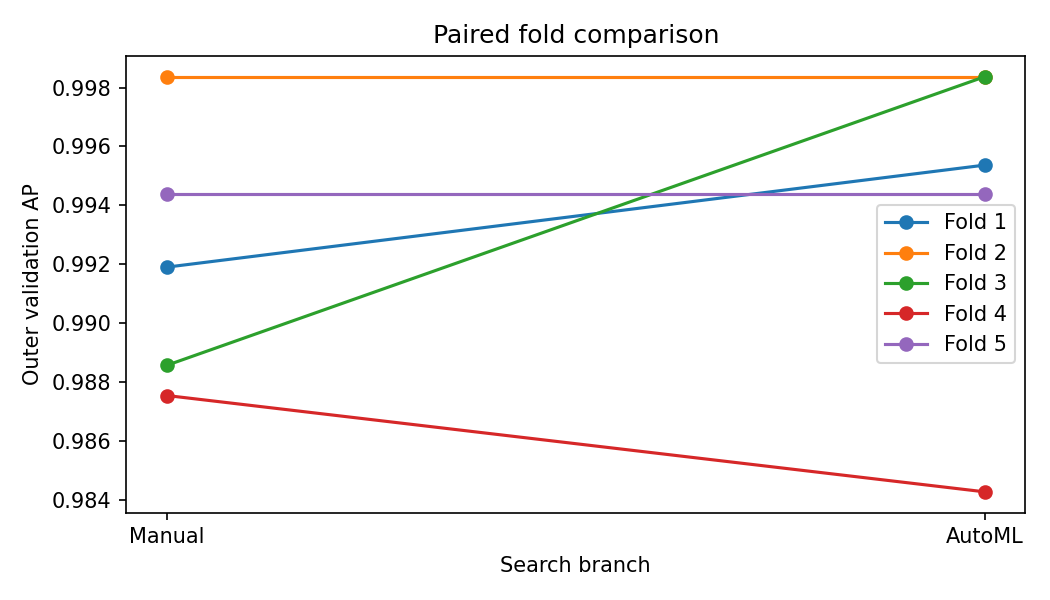

mean d = 0.001999  within epsilon: True  max |d_j| = 0.009801


In [5]:
fm=table('fold_metrics');display(fm.round(4))
display(table('cv_summary').round(4))
cmp_=record('paired_comparison');display(cmp_)
picture('01_ap_distribution')
picture('02_paired_ap')
oof=table('oof_predictions')
assert len(oof)==455 and oof.id.is_unique and not oof.isna().any().any()
for row in fm.itertuples():
    g=oof[oof.fold.eq(row.fold)]
    assert np.isclose(E.probability_metrics(g.y,g[row.branch])['ap'],row.ap)
ap=fm.pivot(index='fold',columns='branch',values='ap')
d=(ap.automl-ap.manual).to_numpy()
assert np.allclose(d,cmp_['difference_automl_minus_manual']) and np.isclose(d.mean(),cmp_['mean_difference'])
assert np.allclose(E.bootstrap_mean_interval(d),cmp_['bootstrap_interval_95'])
print('mean d =',round(d.mean(),6),' within epsilon:',abs(d.mean())<=cmp_['epsilon'],' max |d_j| =',round(np.abs(d).max(),6))
assert (ap.manual>ap.baseline).all() and (ap.automl>ap.baseline).all()

Обидві гілки на всіх п'яти outer-folds значно перевищують prior baseline. Середня парна різниця AutoML − Manual менша за ε,
інтервал bootstrap містить нуль, і жодна окрема різниця не перевищує ε. П'ять залежних folds — малий матеріал:
bootstrap тут описовий, а не доказ еквівалентності. Для folds 1 і 4 обидві гілки вибрали однаковий pipeline, тому різниця дорівнює нулю.

## 5. Стійкість пошуку й OOF-поведінка
Три фінальні searches змінюють seed splitter і FLAML; моделі з випадковістю мають random_state=42.
Seed=42 наперед визначено операційним; 43 і 44 не використовуються для перевибору після test.
Розбіжність фінальних моделей на train — описова й оптимістична для узагальнення; якість оцінюється outer OOF.

,seed,branch,family,inner_ap,params
0,42,manual,lrl2,0.994760,"{""C"": 1.0}"
1,42,automl,lrl2,0.993049,"{""C"": 0.1, ""class_weight"": null}"
2,43,manual,lrl2,0.993573,"{""C"": 1.0}"
3,43,automl,lrl2,0.993400,"{""C"": 0.1, ""class_weight"": ""balanced""}"
4,44,manual,lrl2,0.993473,"{""C"": 1.0}"
5,44,automl,lrl2,0.993611,"{""C"": 0.1, ""class_weight"": ""balanced""}"


{'on': 'full train; descriptive fitted-model comparison, not a generalization estimate',
 'pairwise_disagreement': {'manual': [0.0, 0.0, 0.0],
  'automl': [0.008791208791208791, 0.008791208791208791, 0.0]}}

,fold,branch,family,params,inner_ap
0,0,manual,lrl2,"{""C"": 1.0}",0.993517
1,0,automl,lrl2,"{""C"": 0.1, ""class_weight"": null}",0.992525
2,1,manual,lrl2,"{""C"": 0.1}",0.989901
3,1,automl,lrl2,"{""C"": 0.1, ""class_weight"": null}",0.989901
4,2,manual,histgb,"{""learning_rate"": 0.1, ""max_iter"": 100, ""max_l...",0.990728
5,2,automl,lrl2,"{""C"": 0.1, ""class_weight"": null}",0.989892
6,3,manual,lrl2,"{""C"": 1.0}",0.996078
7,3,automl,lrl2,"{""C"": 0.1, ""class_weight"": null}",0.995011
8,4,manual,lrl2,"{""C"": 0.1}",0.990510
9,4,automl,lrl2,"{""C"": 0.1, ""class_weight"": null}",0.990510


,category,n
0,both_correct,439
1,both_wrong,12
2,only_automl_correct,3
3,only_manual_correct,1


,id,y,fold,manual,automl,baseline,category,probability_gap
0,491,0,2,0.913069,0.191722,0.373626,only_automl_correct,0.721347
1,261,1,2,0.996526,0.683909,0.373626,both_correct,0.312617
2,489,1,2,0.994479,0.685723,0.373626,both_correct,0.308756
3,526,0,2,0.036641,0.329018,0.373626,both_correct,0.292377
4,126,1,2,0.983986,0.693408,0.373626,both_correct,0.290579


records with probability gap >0.2: 17 | >0.5: 1


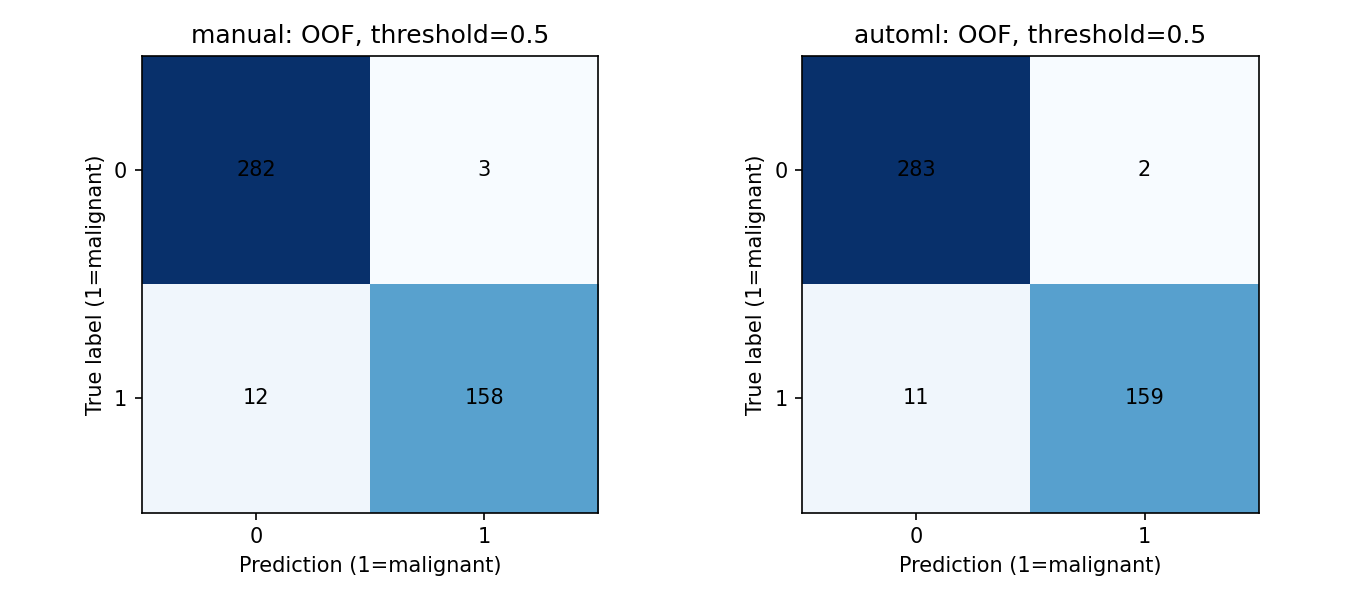

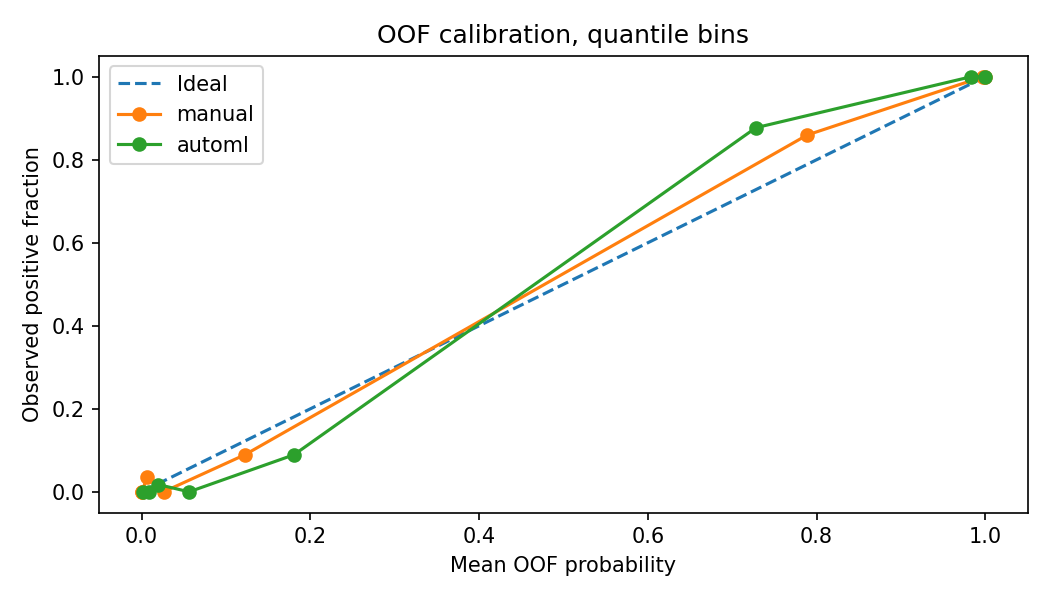

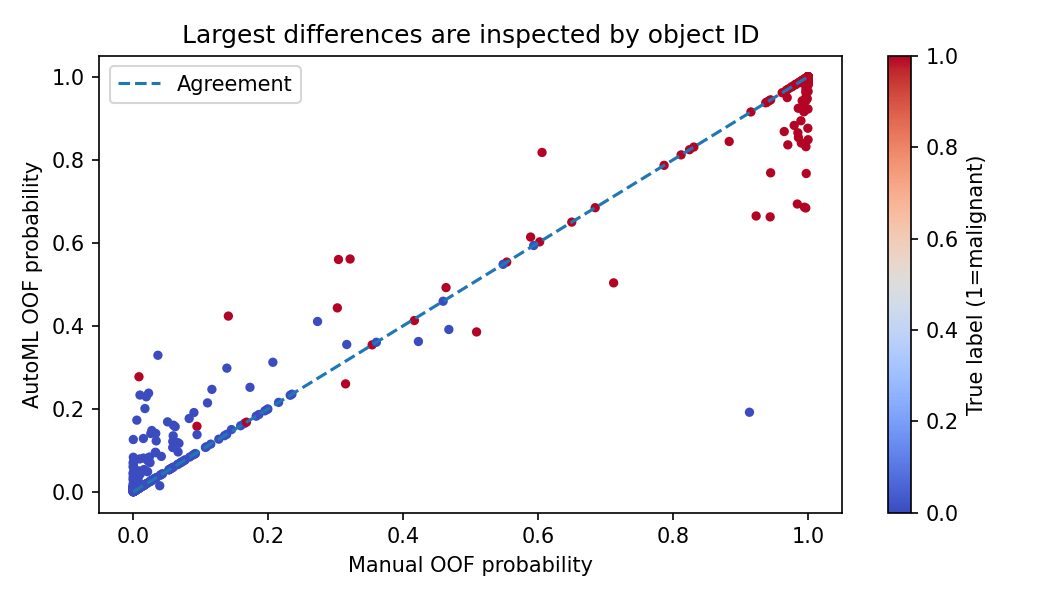

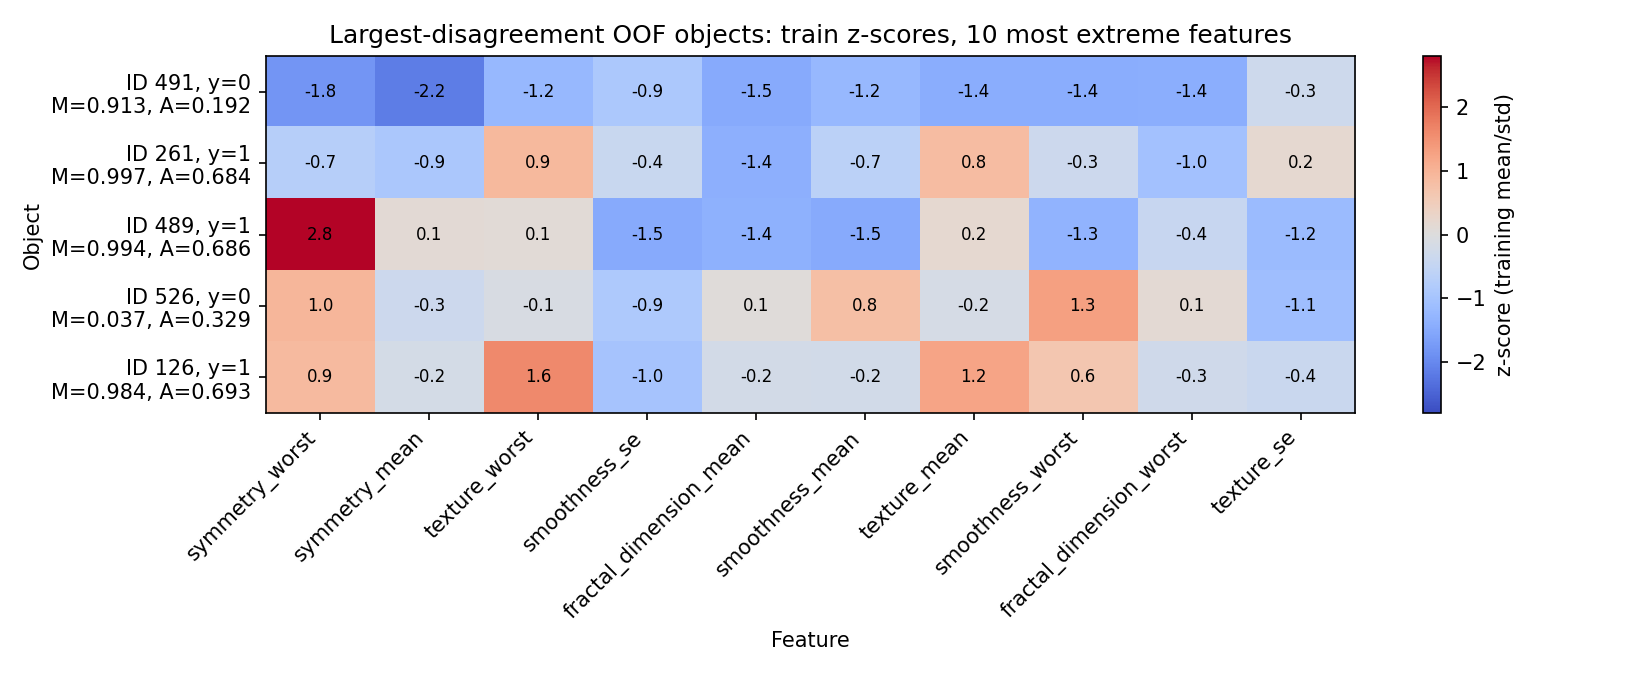

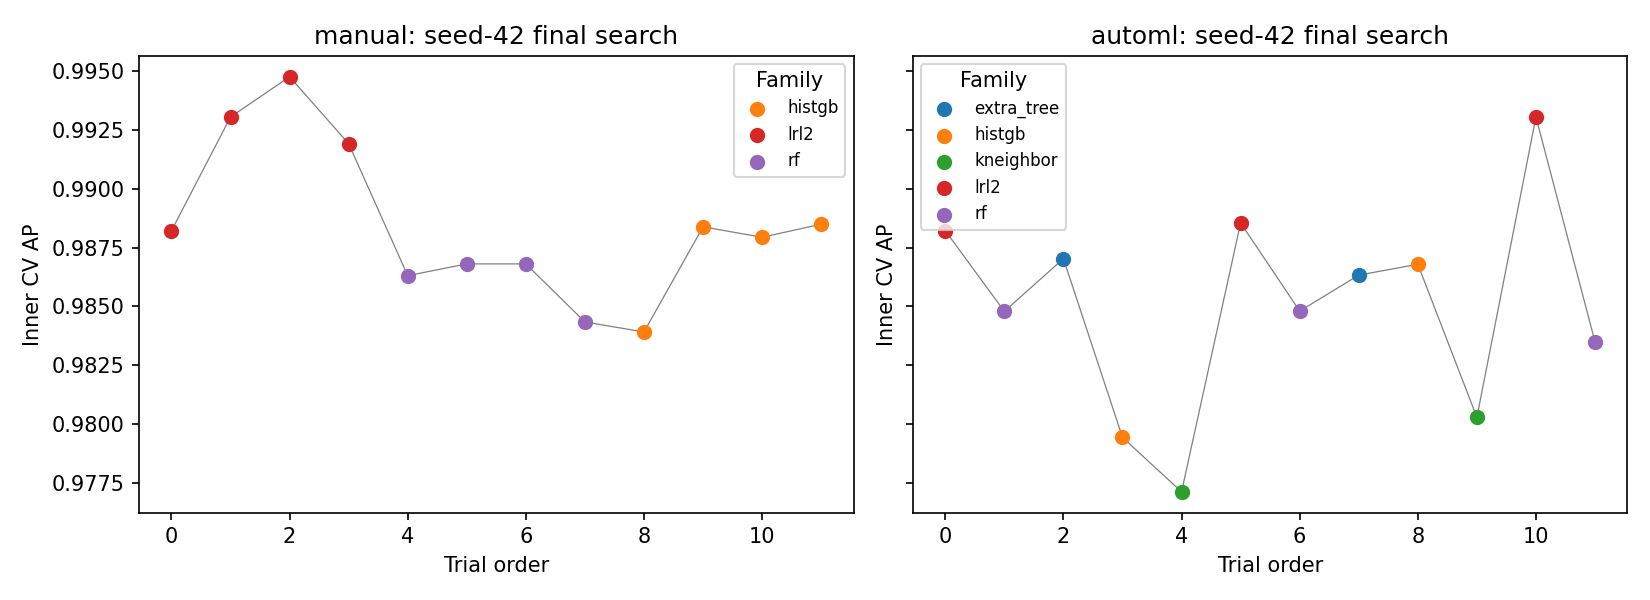

In [6]:
display(table('search_stability').round(6))
display(record('seed_disagreement'))
ow=pd.DataFrame([{'fold':r['fold'],'branch':r['branch'],'family':r['spec']['family'],'params':json.dumps(r['spec']['params']),'inner_ap':round(r['inner_ap'],6)} for r in json.loads((ROOT/'results/outer_winners.json').read_text(encoding='utf-8'))])
display(ow)
stab=table('search_stability')
assert (stab.family=='lrl2').all()
display(table('behavior_summary'))
display(table('largest_disagreements').round(6))
b=oof.copy();pm=b.manual>=.5;pa=b.automl>=.5;cm_=pm==b.y;ca=pa==b.y
cat=np.select([cm_&ca,~cm_&~ca,cm_&~ca],['both_correct','both_wrong','only_manual_correct'],default='only_automl_correct')
bs=table('behavior_summary').set_index('category').n.to_dict()
assert pd.Series(cat).value_counts().to_dict()==bs and sum(bs.values())==455
beh=table('oof_behavior')
print('records with probability gap >0.2:',int((beh.probability_gap>0.2).sum()),'| >0.5:',int((beh.probability_gap>0.5).sum()))
picture('04_confusion_matrices')
picture('03_calibration')
picture('06_probability_disagreement')
picture('07_disagreement_objects')
picture('08_candidate_history')

Обидві гілки у всіх трьох фінальних searches вибрали `lrl2`; змінюються лише параметри (Manual: C=1.0; AutoML: C=0.1,
`class_weight` null для seed 42 і balanced для 43/44). Тому на цьому наборі гіпотеза про нестійке сімейство переможця **не підтверджується**.
Це властивість саме цього набору й простору, а не загальне твердження про AutoML.
У OOF мітки на порозі 0.5 різняться лише в 4 записах із 455; 12 записів помиляються в обох гілках.
Усі п'ять найбільших розбіжностей ймовірностей — з fold 2, де Manual обрав HistGradientBoosting, а AutoML — логістичну регресію.
Історія кандидатів (рисунок 8) — діагностика пошуку; вона обчислена на тих самих inner folds, що й добір, тому
не придатна для повторного вибору моделі.

## 6. Важливість на відкладених folds
Permutation importance рахується тільки на outer-validation, 5 перестановок, seed=42, показник — падіння AP.
Корельовані ознаки можуть ділити важливість; це чутливість прогнозу, а не причинний ефект.

branch,automl,manual
feature,,
texture_worst,0.006762,0.008267
perimeter_worst,0.001613,0.004042
area_se,0.002021,0.003542
radius_se,0.003121,0.002827
symmetry_worst,0.002382,0.002814
texture_mean,0.003156,0.002441
concave_points_mean,0.001499,0.001955
concavity_worst,0.001141,0.001746
compactness_se,0.001672,0.001734


branch,automl,manual
feature,,
texture_worst,0.006762,0.008267
texture_mean,0.003156,0.002441
radius_se,0.003121,0.002827
symmetry_worst,0.002382,0.002814
radius_worst,0.002228,0.001326
area_se,0.002021,0.003542
area_worst,0.001933,0.001139
smoothness_worst,0.001700,0.000975
compactness_se,0.001672,0.001734


Top-10 Jaccard: 6 / 14 = 0.428571 ['area_se', 'compactness_se', 'radius_se', 'symmetry_worst', 'texture_mean', 'texture_worst']


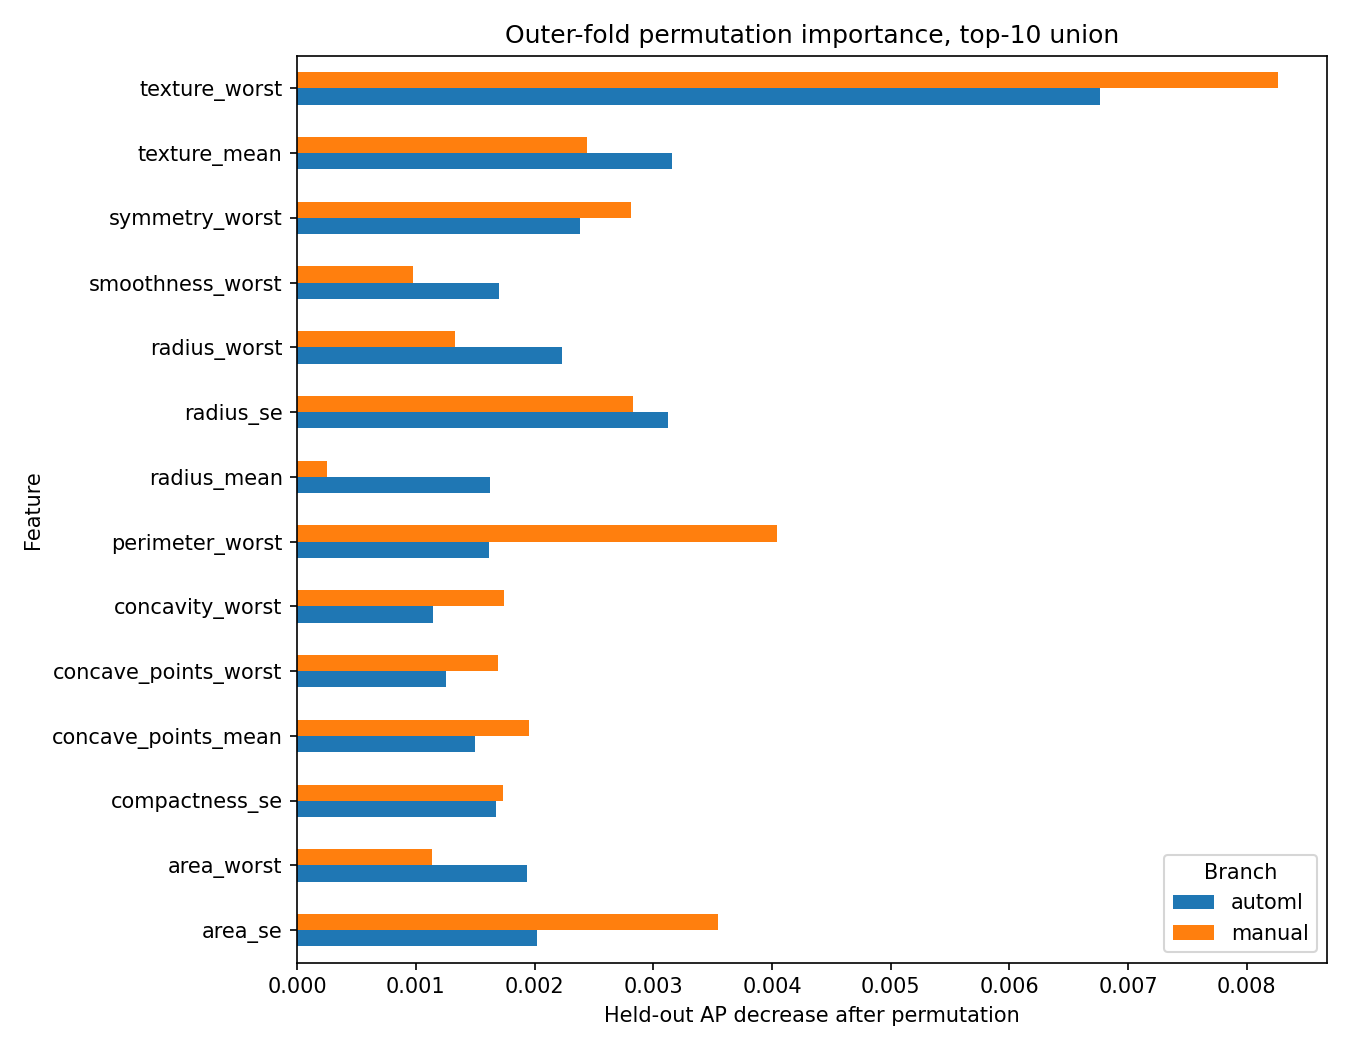

In [7]:
imp=table('permutation_importance');assert len(imp)==300
means=imp.groupby(['branch','feature']).importance.mean().unstack('branch')
display(means.nlargest(10,'manual').round(6))
display(means.nlargest(10,'automl').round(6))
a=set(means.manual.nlargest(10).index);c=set(means.automl.nlargest(10).index)
print('Top-10 Jaccard:',len(a&c),'/',len(a|c),'=',round(len(a&c)/len(a|c),6),sorted(a&c))
assert np.isclose(len(a&c)/len(a|c),record('summary')['top10_jaccard'])
picture('05_permutation_importance')

## 7. Інженерні характеристики і рішення до test
Обидва фіналісти збережені як повні sklearn Pipeline без стану AutoML-пошуку.
Latency: 7 прогрівів, 45 вимірювань, один потік; пакети 1 і 256; одне середовище, p95 з 45 вимірювань чутливий до поодиноких викидів.
Рішення записане й захешоване до першого `predict` на test; `test_metrics_present=False`.

In [8]:
eng=table('engineering');display(eng.round(5))
decision=record('decision_record');display({k:decision[k] for k in ['selected_branch','candidate_id','family','params','epsilon','tie_break','reason','test_metrics_present']})
digest=E.sha256_file(ROOT/'results/decision_record.json')
print('Decision SHA-256:',digest)
assert digest==(ROOT/'results/decision.sha256').read_text().strip()
assert decision['test_metrics_present'] is False
assert decision['config_sha256']==E.sha256_file(ROOT/'configs/experiment.json')
delta=decision['cv_evidence']['mean_difference']
if abs(delta)<=decision['epsilon']:
    expected=eng.sort_values(['size_bytes','single_p95_ms','branch']).iloc[0].branch
    assert expected==decision['selected_branch']
print('size difference, bytes:',int(eng.size_bytes.max()-eng.size_bytes.min()),'| first criterion decided the tie-break')

,branch,search_seconds,fit_seconds,size_bytes,single_p50_ms,single_p95_ms,batch256_p50_ms,batch256_p95_ms
0,manual,3.23296,0.01043,2174,0.4186,2.55132,0.7381,1.88782
1,automl,1.42859,0.00549,2171,0.4221,0.93206,0.4960,1.29962


{'selected_branch': 'automl',
 'candidate_id': 'automl_seed42_trial10',
 'family': 'lrl2',
 'params': {'C': 0.1, 'class_weight': None},
 'epsilon': 0.01,
 'tie_break': 'smaller serialized pipeline, then lower p95 single latency, then manual',
 'reason': 'Mean paired AP difference +0.001999 is within epsilon 0.01; tie-break applied: smaller serialized pipeline, then lower p95 single latency, then manual. This is not proof of equivalence.',
 'test_metrics_present': False}

Decision SHA-256: 62caba19558d196bdefb4b1b459d8d6ba1809f5d1f0aa9b7450401380a5a584c
size difference, bytes: 3 | first criterion decided the tie-break


Рішення прийнято механічно за наперед заданим правилом: різниця AP в межах ε, тож обрано менший файл — AutoML (2171 проти 2174 байт).
Різниця в 3 байти практично не має змісту, а якість еквівалентна; обидва фіналісти — логістична регресія L2, тому критерій
розміру тут вироджений. Правило не змінювалось після результатів. p95 single-latency відрізняється, але до цього критерію
правило не дійшло; p50 майже однаковий.

## 8. Test і пакет передачі
Фінальний test оцінюється для вибраної гілки один раз. Інший фіналіст оцінений на test лише після заморожування рішення,
виключно для аудиту; він не впливав на вибір.

In [9]:
tm=record('test_metrics');display(tm)
t=table('test_predictions');actual=E.probability_metrics(t.y,t.probability)
for key,value in actual.items(): assert np.isclose(value,tm[key])
assert sorted(t.id)==sorted(te) and tm['n']==114 and tm['positive_n']==42
assert tm['decision_sha256']==digest
other=record('test_audit_other_finalist');display(other)
assert other['AUDIT_ONLY'] is True and other['branch']!=decision['selected_branch'] and other['decision_sha256']==digest
print('Handoff files:',sorted(p.name for p in (ROOT/'handoff').iterdir()))
assert E.sha256_file(ROOT/'handoff/decision_record.json')==digest
ex=json.loads((ROOT/'handoff/inference_example.json').read_text())
import joblib
from inference import predict
loaded=joblib.load(ROOT/'handoff/pipeline.joblib')
np.testing.assert_allclose(predict(loaded,ex['input']),ex['expected_probability'],rtol=1e-10,atol=1e-12)
cv=table('cv_summary').set_index('branch').loc[decision['selected_branch']]
print('CV AP',round(cv.ap_mean,4),'+-',round(cv.ap_std,4),'| test AP',round(tm['ap'],4))

{'branch': 'automl',
 'n': 114,
 'positive_n': 42,
 'threshold': 0.5,
 'ap': 0.9965986394557824,
 'roc_auc': 0.9976851851851852,
 'f1': 0.975609756097561,
 'precision': 1.0,
 'recall': 0.9523809523809523,
 'balanced_accuracy': 0.9761904761904762,
 'brier': 0.023365471064195696,
 'log_loss': 0.09478851049675145,
 'confusion_matrix': [[72, 0], [2, 40]],
 'decision_sha256': '62caba19558d196bdefb4b1b459d8d6ba1809f5d1f0aa9b7450401380a5a584c'}

{'AUDIT_ONLY': True,
 'note': 'Evaluated after the decision freeze. Not used for selection, tuning or reporting of the selected model.',
 'branch': 'manual',
 'candidate_id': 'manual_02',
 'family': 'lrl2',
 'n': 114,
 'positive_n': 42,
 'threshold': 0.5,
 'ap': 0.994273631904294,
 'roc_auc': 0.996031746031746,
 'f1': 0.9512195121951219,
 'precision': 0.975,
 'recall': 0.9285714285714286,
 'balanced_accuracy': 0.9573412698412699,
 'brier': 0.021313139001192274,
 'log_loss': 0.0772650126161056,
 'confusion_matrix': [[71, 1], [3, 39]],
 'decision_sha256': '62caba19558d196bdefb4b1b459d8d6ba1809f5d1f0aa9b7450401380a5a584c'}

Handoff files: ['MODEL_CARD.md', 'config.json', 'cv_metrics.csv', 'data_provenance.json', 'data_schema.json', 'decision.sha256', 'decision_record.json', 'environment.json', 'inference.py', 'inference_example.json', 'pipeline.joblib', 'requirements.txt', 'split_ids.csv', 'test_metrics.json']
CV AP 0.9942 +- 0.0058 | test AP 0.9966


## 9. Висновок
Обидві гілки перевищили baseline. Середня парна різниця AP AutoML − Manual (0.0020) менша за ε=0.01, інтервал bootstrap містить нуль,
тож якість практично еквівалентна; це не доказ еквівалентності. Наперед заданий tie-break за розміром обрав AutoML (логістична регресія L2, C=0.1)
через 3 байти різниці — вибір практично довільний. Це не означає, що AutoML кращий.
Обидві гілки стабільно обирали `lrl2` для seeds 42, 43, 44; це властивість цього набору.
Test: AP 0.9966, F1 0.9756, recall 0.9524, матриця [[72, 0], [2, 40]]; другий фіналіст оцінений лише для аудиту.
Обмеження для ЛР № 7: одне джерело з 569 записів без групування за пацієнтами, фіксований поріг 0.5, повторне використання набору в курсі,
мала історія пошуку, невелика нестійкість рангу важливості. Поточний test не слід використовувати для подальшого підбору порога чи калібрування.
Команди й тести — у README.